In [3]:
import os
import re
import sys

sys.path.append("../")

import analysis
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import periodogram, welch, find_peaks
from scipy.optimize import curve_fit as fit

base_path = r"C:\Users\sl57562\The University of Texas at Austin\Acoustic + Calcium - Documents\Acoustic\piezo_char_2nd_10-6-26\20261006"

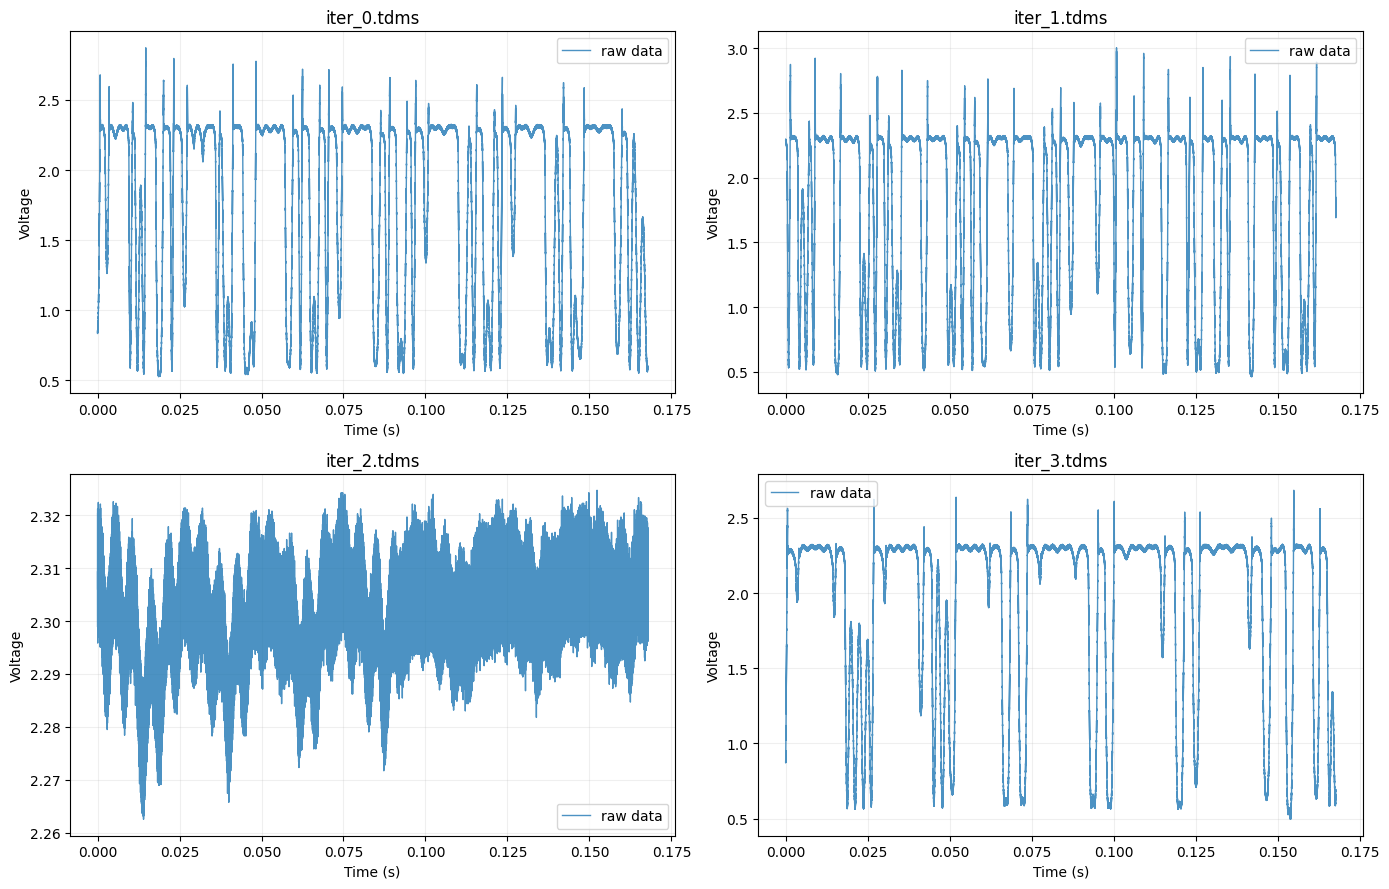

In [6]:
file_name = "piezo_char_1V_109kHz_calibration"
cal_dir = os.path.join(base_path, file_name)

# Load the 4 TDMS files in the calibration folder.
tdms_files = sorted(
    os.path.join(cal_dir, fname)
    for fname in os.listdir(cal_dir)
    if fname.lower().endswith(".tdms")
)
num = len(tdms_files)

tdms_files = tdms_files[:num]


def sinusoid(t, amp, phase, freq, offset):
    return amp * np.sin(2 * np.pi * freq * t + phase) + offset

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, tdms_file in zip(axes, tdms_files):
    d = analysis.ctdms(tdms_file)
    d.set_collection("X")
    col = d.collection[0]

    t = np.asarray(col.t)
    y = np.asarray(col.x)

    ax.plot(t, y, label="raw data", linewidth=1.0, alpha=0.8)
    ax.set_title(os.path.basename(tdms_file))
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Voltage")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()